In [1]:
import pyspark, os, sys, pandas as pd
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
import pyspark.sql.types as T
os.environ['PYSPARK_PYTHON'] = os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
STREAM_HOST = os.environ.get("SOCKET_HOST", "localhost")
print("Python", sys.executable)
print("Java", os.environ["JAVA_HOME"])
spark = SparkSession.builder.appName("spark-structured-streaming-preparation").getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")
spark.conf.set("spark.sql.shuffle.partitions", "4")    # the default of 200 makes each micro-batch slow
spark.conf.set("spark.sql.session.timeZone", "UTC")    # the simulators write UTC timestamps
print("Spark version:", spark.version)
spark

Python /usr/local/bin/python
Java /usr/lib/jvm/java-17-openjdk-amd64


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/01 20:06:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.1.2


# Event Time, Windows, and Watermarks

Streaming data carries two distinct notions of time:

| Time type | Definition | Example |
|-----------|-----------|--------|
| **Processing time** | When the event arrives at Spark | System clock at ingestion |
| **Event time** | When the event actually *happened* | Sensor measurement timestamp |

Using **event time** is essential for correct analytics because:
- Network delays, retries, or offline devices can deliver events late.
- A "page views per minute" metric should count by when views happened, not when they were ingested.

Structured Streaming handles event time with two mechanisms:
1. **`window(col, duration[, slide])`** -- groups events into fixed or sliding time buckets.
2. **`withWatermark(col, delay)`** -- tells Spark how long to wait for late data before closing a window.

**What we will do in this session**

| Example | Question it answers | Simulator |
|---------|---------------------|-----------|
| 1. IoT sensors | What does late data look like, and when does Spark count it or drop it? | `sensor_simulator.py` |
| 2. Word count | How do tumbling and sliding windows differ on the same stream? | `word_simulator.py` |
| 3. Watermarks in depth | Can we predict every decision Spark makes, event by event? | `late_event_replay.py` |
| 4. Deduplication | When a reading arrives twice, how does Spark recognise it, and for how long? | `duplicate_replay.py` |

# Window Types

```
Tumbling window (non-overlapping):
  window("ts", "5 minutes")
  │◄─ 5 min ─►│◄─ 5 min ─►│◄─ 5 min ─►│
  [00:00─00:05)[00:05─00:10)[00:10─00:15)
  An event at 00:07 belongs to exactly one window: [00:05─00:10)

Sliding window (overlapping):
  window("ts", "10 minutes", "5 minutes")   # 10-min window, slides every 5 min
  │◄──── 10 min ────►│
       │◄──── 10 min ────►│
            │◄──── 10 min ────►│
  [00:00─00:10)
     [00:05─00:15)
        [00:10─00:20)
  An event at 00:07 belongs to two windows: [00:00─00:10) and [00:05─00:15)
```

Each window includes its start and excludes its end.

# How a Watermark Decides

A watermark answers one question: *how long should Spark keep a window open, in case more of its events are still on the way?*

With `.withWatermark("event_time", "10 seconds")` Spark follows three rules:

1. **Move the watermark.** At the end of each micro-batch:
   `watermark = newest event time seen so far - 10 seconds`
   It only ever moves forward, and it only moves when newer events arrive.
2. **Close windows.** A window closes once `window end <= watermark`. Spark emits its final result (in `append` mode) and frees its memory.
3. **Judge late events by their window.** An arriving event is dropped only if the window it belongs to has already closed.

Three details surprise people, and they matter for the rest of this notebook:

- The test is on the **window**, not on the event's own timestamp. An event older than the watermark is still counted if its window is open.
- Within a micro-batch the watermark never changes, and Spark **counts first and closes windows last**. A window that closes in this batch still accepts this batch's rows.
- So a watermark is a **minimum wait, not an exact cutoff**. `"10 seconds"` guarantees that events up to 10 seconds late are counted. Later events are *probably* dropped, but some will survive, as we will measure.

### Why `trigger(availableNow=True)` cannot show this

`availableNow` reads everything already in the folder and then stops. If the on-time events and the late events are all waiting there, they land in the same micro-batch, so the watermark never gets a chance to move between them. Nothing is late, nothing is dropped, and the demo proves nothing.

To see a watermark at work, events have to arrive **over time, while the query is running**. That is what the simulators are for.

In [20]:
input_stream = (spark.readStream
    .format("socket")
    .option("host", STREAM_HOST)
    .option("port", 11111)
    .load())

word_counts = (input_stream
     .withColumn("arrived_at", F.current_timestamp())
     #.withWatermark("arrived_at", "5 seconds")
    .withColumn("word", F.explode(F.split(F.lower(F.col("value")), r"\W+")))
    .where(F.length("word") > 0)
    .groupBy("word",
            F.window("arrived_at", "15 seconds")
            ).count())

q_complete = (
    word_counts.writeStream.format("console")
    .option("truncate", False)
    .outputMode("update") # try append
    .trigger(processingTime="10 seconds").start()
)

q_complete.awaitTermination(40)
q_complete.stop()

-------------------------------------------
Batch: 0
-------------------------------------------
+----+------+-----+
|word|window|count|
+----+------+-----+
+----+------+-----+

-------------------------------------------
Batch: 1
-------------------------------------------
+----+------+-----+
|word|window|count|
+----+------+-----+
+----+------+-----+

-------------------------------------------
Batch: 2
-------------------------------------------
+----+------+-----+
|word|window|count|
+----+------+-----+
+----+------+-----+

-------------------------------------------
Batch: 3
-------------------------------------------
+----+------------------------------------------+-----+
|word|window                                    |count|
+----+------------------------------------------+-----+
|cat |{2026-11-01 20:29:00, 2026-11-01 20:29:15}|1    |
+----+------------------------------------------+-----+

-------------------------------------------
Batch: 4
-----------------------------------

# The Simulators

Each script drops small files into a folder under `tmp/`, one every second or two, and Spark watches that folder. Late data is created the way it happens in real life: the event gets its timestamp when it happens, but the simulator holds it back, so it reaches Spark later.

| Script | Sends | Controls late data with |
|--------|-------|------------------------|
| `sensor_simulator.py` | 3 sensors, one reading per second each | `--late-seconds 8 25`, `--late-every 20` |
| `word_simulator.py` | One line of the poem every 2 seconds | `--late-seconds 12`, `--late-every 5` |
| `late_event_replay.py` | A fixed script of 5 batches | `--no-late`, `--step` |
| `duplicate_replay.py` | A fixed script of 5 batches with retries | `--no-duplicates`, `--step` |

Run any of them with `--help` to see every option.

**How to run each demo**

1. Open a terminal in the project folder. Windows or the Jupyter terminal both work, and the scripts need nothing beyond Python.
   In the Jupyter terminal, run `cd /app/work` first.
2. Run the notebook cell. It starts the streaming query and prints the command to use.
3. When you see **`START THE SIMULATOR NOW`**, run that command in the terminal.
4. The cell shows the results as they arrive. It stops by itself about 15 seconds after the data stops, and the kernel's stop button also ends it cleanly.

The order matters: **start the query first, then the simulator.** Otherwise the files pile up and Spark reads them all in one batch, which is the `availableNow` problem again.

The next cell defines two helpers. `watch()` prints one line under each console table, showing what Spark did in that micro-batch.

In [2]:
import shutil, time

def reset(*folders):
    """Empty the given folders so that each demo starts clean."""
    for folder in folders:
        shutil.rmtree(folder, ignore_errors=True)
        os.makedirs(folder)

def clock(iso_time):
    """'2026-10-31T20:41:04.000Z' -> '20:41:04'"""
    return iso_time[11:19] if iso_time else "-"

def describe_batch(progress):
    """One line summarising a micro-batch, read from Spark's own progress report."""
    event_time = progress["eventTime"]
    parts = [f"{progress['numInputRows']} rows arrived"]
    if event_time.get("max"):
        parts.append(f"newest event {clock(event_time['max'])}")
    if progress["stateOperators"]:
        state = progress["stateOperators"][0]
        watermark = event_time.get("watermark", "1970")        # Spark reports 1970 until one exists
        parts.append(f"watermark {'not set yet' if watermark.startswith('1970') else clock(watermark)}")
        parts.append(f"LATE ROWS DROPPED {state['numRowsDroppedByWatermark']}")
        duplicates = dict(state["customMetrics"]).get("numDroppedDuplicateRows")
        if duplicates is not None:                             # only deduplication queries report this
            parts.append(f"DUPLICATES DROPPED {duplicates}")
        parts.append(f"groups closed {state['numRowsRemoved']}")
        parts.append(f"groups open {state['numRowsTotal']}")
    return " | ".join(parts)

def watch(*queries, cue=None, max_seconds=150, idle_seconds=15):
    """Report on running queries until the data stops, then stop them."""
    if cue:
        print(f"START THE SIMULATOR NOW:   {cue}\n", flush=True)
    reported, last_data, started = set(), None, time.time()
    try:
        while time.time() - started < max_seconds:
            for query in queries:
                if query.exception():
                    raise RuntimeError(query.exception())
                for progress in query.recentProgress:
                    ran = "addBatch" in progress["durationMs"]     # skip idle "nothing to do" reports
                    if not ran or progress["id"] + progress["timestamp"] in reported:
                        continue
                    reported.add(progress["id"] + progress["timestamp"])
                    if progress["numInputRows"] > 0:
                        last_data = time.time()
                    label = f"{query.name}, " if len(queries) > 1 else ""
                    print(f">> [{label}batch {progress['batchId']}] {describe_batch(progress)}\n", flush=True)
            if last_data and time.time() - last_data > idle_seconds:
                break
            time.sleep(0.5)
    finally:
        for query in queries:
            query.stop()
    print("Query stopped.")

# Example 1: IoT Sensors -- Late Data in a Tumbling Window

Sensors send `sensorID, event_time, temperature`. We want the **average temperature per sensor in 5-second windows**, and we are willing to wait **10 seconds** for stragglers.

There is one extra column, `late_by`. Only the simulator knows it, and we use it to spot late rows in the output. Spark's watermark never looks at it.

We go through this in three steps:

1. Look at the raw stream, to see events arriving out of order.
2. Aggregate to the console in `update` mode, to watch late rows change results.
3. Write to files in `append` mode, then measure what was lost.

In [3]:
SENSOR_DIR  = "tmp/sensor_stream"
SENSOR_CKPT = "tmp/sensor_ckpt"
SENSOR_OUT  = "out/sensor_windows"
reset(SENSOR_DIR)

sensor_schema = T.StructType([
    T.StructField("sensorID",    T.IntegerType()),
    T.StructField("event_time",  T.TimestampType()),
    T.StructField("temperature", T.DoubleType()),
    T.StructField("late_by",     T.IntegerType()),
])

# The schema is required: the folder is empty, so Spark has nothing to infer it from
sensor_stream = spark.readStream.schema(sensor_schema).csv(SENSOR_DIR)
print("Is streaming:", sensor_stream.isStreaming)

Is streaming: True


## Step 1: See event time and processing time side by side

This query has no window and no watermark. It prints each row as it arrives, with `arrived_at` taken from Spark's clock. Normally `delay_s` is a few seconds, because a row waits for the next 5-second trigger. Rows the simulator held back stand out with a much larger delay and an old `event_time`.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python sensor_simulator.py --duration 20 --late-seconds 8 --late-every 8
> ```

In [6]:
reset(SENSOR_DIR, SENSOR_CKPT)

raw_view = (
    sensor_stream
    .withColumn("arrived_at", F.current_timestamp())
    .select(
        "sensorID",
        F.date_format("event_time", "HH:mm:ss").alias("event_time"),
        F.date_format("arrived_at", "HH:mm:ss").alias("arrived_at"),
        (F.col("arrived_at").cast("long") - F.col("event_time").cast("long")).alias("delay_s"),
        "temperature",
        "late_by",
    )
)

q = (
    raw_view.writeStream
    .format("console")
    .outputMode("append")
    .option("truncate", False)
    .option("numRows", 25)
    .option("checkpointLocation", SENSOR_CKPT)
    .trigger(processingTime="5 seconds")
    .start()
)
watch(q, cue="python sensor_simulator.py --duration 20 --late-seconds 8 --late-every 8")

START THE SIMULATOR NOW:   python sensor_simulator.py --duration 20 --late-seconds 8 --late-every 8

-------------------------------------------
Batch: 0
-------------------------------------------
+--------+----------+----------+-------+-----------+-------+
|sensorID|event_time|arrived_at|delay_s|temperature|late_by|
+--------+----------+----------+-------+-----------+-------+
|1       |20:12:13  |20:12:15  |2      |65.28      |0      |
|2       |20:12:13  |20:12:15  |2      |65.14      |0      |
|3       |20:12:13  |20:12:15  |2      |65.44      |0      |
|1       |20:12:14  |20:12:15  |1      |69.51      |0      |
|2       |20:12:14  |20:12:15  |1      |65.36      |0      |
|3       |20:12:14  |20:12:15  |1      |58.51      |0      |
+--------+----------+----------+-------+-----------+-------+

>> [batch 0] 6 rows arrived | newest event 20:12:14

-------------------------------------------
Batch: 1
-------------------------------------------
+--------+----------+----------+-------+-

**What to notice:** the rows are not in event-time order. A row from several seconds ago can land next to brand-new rows. If we grouped by `arrived_at`, those readings would be counted in the wrong time period.

## Step 2: Tumbling window, to the console, in `update` mode

`update` mode prints every window that **changed** in this micro-batch, so we can watch a late reading arrive. A late reading makes an old window reappear with a higher count.

The simulator takes turns between two kinds of late reading:

| Delay | Against our 10-second watermark | Expected outcome |
|-------|--------------------------------|------------------|
| 8 seconds | Its window is still open | Counted: an old window reappears with `late_readings` up by 1 |
| 25 seconds | Its window has closed | Dropped: the `LATE ROWS DROPPED` figure goes up, and no table changes |

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python sensor_simulator.py --duration 60 --late-seconds 8 25
> ```
> Keep the terminal visible. Each `HOLD` line is a reading being delayed, and each `LATE` line is it finally arriving. Find the same moment in the notebook.

In [7]:
def sensor_windows():
    return (
        sensor_stream
        .withWatermark("event_time", "10 seconds")           # wait up to 10 s for stragglers
        .groupBy(
            F.window("event_time", "5 seconds"),             # 5-second tumbling window
            F.col("sensorID"),
        )
        .agg(
            F.round(F.avg("temperature"), 2).alias("avg_temp"),
            F.count("*").alias("readings"),
            F.sum(F.when(F.col("late_by") > 0, 1).otherwise(0)).alias("late_readings"),
        )
    )

reset(SENSOR_DIR, SENSOR_CKPT)

console_view = sensor_windows().select(
    F.date_format("window.start", "HH:mm:ss").alias("window_start"),
    F.date_format("window.end", "HH:mm:ss").alias("window_end"),
    "sensorID", "avg_temp", "readings", "late_readings",
)

q = (
    console_view.writeStream
    .format("console")
    .outputMode("update")
    .option("truncate", False)
    .option("numRows", 30)
    .option("checkpointLocation", SENSOR_CKPT)
    .trigger(processingTime="5 seconds")
    .start()
)
watch(q, cue="python sensor_simulator.py --duration 60 --late-seconds 8 25")

START THE SIMULATOR NOW:   python sensor_simulator.py --duration 60 --late-seconds 8 25

-------------------------------------------
Batch: 0
-------------------------------------------
+------------+----------+--------+--------+--------+-------------+
|window_start|window_end|sensorID|avg_temp|readings|late_readings|
+------------+----------+--------+--------+--------+-------------+
|20:14:10    |20:14:15  |1       |67.48   |3       |0            |
|20:14:10    |20:14:15  |3       |62.96   |3       |0            |
|20:14:10    |20:14:15  |2       |65.05   |3       |0            |
+------------+----------+--------+--------+--------+-------------+

>> [batch 0] 9 rows arrived | newest event 20:14:14 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3

-------------------------------------------
Batch: 1
-------------------------------------------
+------------+----------+--------+--------+--------+-------------+
|window_start|window_end|sensorID|avg_temp|read

**How to read the output**

- A complete window has 5 readings from each sensor. The 5-second trigger and the 5-second windows both line up with the clock, so most windows are printed once. A window with 4 readings is missing one that the simulator held back.
- **Late but in time:** look for a row with `late_readings = 1` whose `window_start` is well behind the newest rows. Spark reopened nothing, because that window never closed. It was held in state for exactly this reason.
- **Too late:** in a batch where `LATE ROWS DROPPED` is above 0, the reading has reached Spark and been thrown away. It appears in no table.
- **Memory stays flat:** `groups open` stops growing after about 20 seconds. Windows are closing as fast as new ones open. Without a watermark, this number would grow forever.

## Step 3: Write results to files in `append` mode

`update` mode shows partial answers. Files need a final answer, so we use `append`, which writes **each window exactly once, after it closes**.

The price is latency. A 5-second window with a 10-second watermark cannot be written until the event time has moved at least 10 seconds past the window's end. The `groups closed` figure shows when rows are written, and it stays at 0 for the first 20 seconds or so.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python sensor_simulator.py --duration 60 --late-seconds 8 25
> ```

In [8]:
reset(SENSOR_DIR, SENSOR_CKPT, SENSOR_OUT)

file_view = sensor_windows().select(
    F.col("window.start").alias("window_start"),
    F.col("window.end").alias("window_end"),
    "sensorID", "avg_temp", "readings", "late_readings",
)

q = (
    file_view.writeStream
    .format("csv")
    .outputMode("append")                    # one final row per window, after it closes
    .option("path", SENSOR_OUT)
    .option("header", "true")
    .option("checkpointLocation", SENSOR_CKPT)
    .trigger(processingTime="5 seconds")
    .start()
)
watch(q, cue="python sensor_simulator.py --duration 60 --late-seconds 8 25")

written_schema = T.StructType([
    T.StructField("window_start",  T.TimestampType()),
    T.StructField("window_end",    T.TimestampType()),
    T.StructField("sensorID",      T.IntegerType()),
    T.StructField("avg_temp",      T.DoubleType()),
    T.StructField("readings",      T.LongType()),
    T.StructField("late_readings", T.LongType()),
])
written = spark.read.option("header", "true").schema(written_schema).csv(SENSOR_OUT)
written.orderBy("window_start", "sensorID").show(12, truncate=False)

START THE SIMULATOR NOW:   python sensor_simulator.py --duration 60 --late-seconds 8 25

>> [batch 0] 12 rows arrived | newest event 20:17:54 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3

>> [batch 1] 14 rows arrived | newest event 20:17:59 | watermark 20:17:44 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 6

>> [batch 2] 14 rows arrived | newest event 20:18:04 | watermark 20:17:49 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 9

>> [batch 3] 16 rows arrived | newest event 20:18:09 | watermark 20:17:54 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 12

>> [batch 4] 14 rows arrived | newest event 20:18:14 | watermark 20:17:59 | LATE ROWS DROPPED 0 | groups closed 3 | groups open 12

>> [batch 5] 15 rows arrived | newest event 20:18:19 | watermark 20:18:04 | LATE ROWS DROPPED 0 | groups closed 3 | groups open 12

>> [batch 6] 14 rows arrived | newest event 20:18:24 | watermark 20:18:09 | LATE ROWS DROPPED 0 | groups closed 3 | gro

**Did Spark lose anything?** The simulator's files are still in the folder, so we can run an ordinary batch query over them to get the true answer, then compare it with what the stream wrote.

In [9]:
# The truth: every row the simulator sent, however late
all_rows = spark.read.schema(sensor_schema).csv(SENSOR_DIR)
truth = (
    all_rows
    .groupBy(F.window("event_time", "5 seconds"), "sensorID")
    .agg(F.count("*").alias("sent"), F.round(F.avg("temperature"), 2).alias("true_avg"))
    .select(F.col("window.start").alias("window_start"), "sensorID", "sent", "true_avg")
)

comparison = (
    truth
    .join(written.select("window_start", "sensorID", "readings", "avg_temp"),
          ["window_start", "sensorID"], "left")
    .withColumn("outcome",
        F.when(F.col("readings").isNull(), "not written: window never closed")
         .when(F.col("readings") < F.col("sent"), "written, but late rows were dropped")
         .otherwise("written, complete"))
)

comparison.groupBy("outcome").count().show(truncate=False)
(comparison
    .where(F.col("outcome") != "written, complete")
    .orderBy("window_start", "sensorID")
    .select(F.date_format("window_start", "HH:mm:ss").alias("window_start"),
            "sensorID", "sent", "readings", "true_avg", "avg_temp", "outcome")
    .show(30, truncate=False))

+-----------------------------------+-----+
|outcome                            |count|
+-----------------------------------+-----+
|written, complete                  |35   |
|not written: window never closed   |9    |
|written, but late rows were dropped|4    |
+-----------------------------------+-----+

+------------+--------+----+--------+--------+--------+-----------------------------------+
|window_start|sensorID|sent|readings|true_avg|avg_temp|outcome                            |
+------------+--------+----+--------+--------+--------+-----------------------------------+
|20:18:00    |1       |5   |4       |65.87   |67.09   |written, but late rows were dropped|
|20:18:15    |2       |5   |4       |65.67   |64.65   |written, but late rows were dropped|
|20:18:30    |3       |5   |4       |67.55   |68.39   |written, but late rows were dropped|
|20:18:40    |1       |5   |4       |67.51   |67.01   |written, but late rows were dropped|
|20:18:55    |1       |5   |NULL    |67.47   |N

**What this shows**

- **`written, complete`** is most windows, including those that received the 8-second-late readings.
- **`written, but late rows were dropped`** is the cost of the 25-second-late readings. `avg_temp` differs from `true_avg`, and nothing in the output file warns you. This is a deliberate trade-off.
- **`not written: window never closed`** covers the final windows. When the simulator stopped, event time stopped too, so the watermark never moved past them. They are not lost, they are waiting in state. A real stream would close them as soon as more data arrived.

**Choosing the delay is a business decision.** A longer watermark loses less data, but results arrive later and more state is held in memory.

**Try it.** Change only the simulator command and predict the result before you run Step 2 or Step 3 again:

| Command | Prediction to test |
|---------|-------------------|
| `python sensor_simulator.py` | No late data, so `late_readings` stays 0 and nothing is dropped |
| `python sensor_simulator.py --late-seconds 8` | Every late reading is counted |
| `python sensor_simulator.py --late-seconds 20` | Every late reading is **still counted**, even though 20 is double the watermark |
| `python sensor_simulator.py --late-seconds 22` | Mixed: some counted, some dropped, depending on where each reading falls in its window |
| `python sensor_simulator.py --late-seconds 25` | Every late reading is dropped |

Why does a reading that is 20 seconds late survive a 10-second watermark? The real tolerance adds up: 10 seconds of watermark, up to 5 seconds until the window ends, and up to 5 more until the next trigger moves things along. With a shorter trigger or window, the tolerance shrinks. **Only the 10 seconds is guaranteed.**

Then change `"10 seconds"` in `sensor_windows()` to `"30 seconds"` and repeat the 25-second run. Rerun the cells from that one onward, because the watermark is part of the query definition.

# Example 2: Word Count -- Tumbling vs Sliding Windows

The same stream, counted two ways:

| | Tumbling | Sliding |
|---|---|---|
| Code | `window("event_time", "10 seconds")` | `window("event_time", "10 seconds", "5 seconds")` |
| Windows overlap? | No | Yes |
| Windows per event | Exactly 1 | 2 here (window size / slide) |
| New window starts every | 10 seconds | 5 seconds |
| Good for | Reports: "words per 10 seconds" | Trends: "words in the last 10 seconds, refreshed every 5" |

First, a small batch example with no streaming at all, to see the windows a single event falls into.

In [8]:
one_event = spark.createDataFrame([("2026-01-01 12:00:17",)], ["ts"]).select(F.to_timestamp("ts").alias("event_time"))

print("One event at 12:00:17, tumbling window:")
one_event.select(F.window("event_time", "10 seconds").alias("w")).select("w.start", "w.end").show(truncate=False)

print("The same event, sliding window:")
one_event.select(F.window("event_time", "10 seconds", "5 seconds").alias("w")).select("w.start", "w.end").show(truncate=False)

One event at 12:00:17, tumbling window:


+-------------------+-------------------+
|start              |end                |
+-------------------+-------------------+
|2026-01-01 12:00:10|2026-01-01 12:00:20|
+-------------------+-------------------+

The same event, sliding window:


+-------------------+-------------------+
|start              |end                |
+-------------------+-------------------+
|2026-01-01 12:00:15|2026-01-01 12:00:25|
|2026-01-01 12:00:10|2026-01-01 12:00:20|
+-------------------+-------------------+



Now the streaming version. The simulator sends one line of the poem every 2 seconds, with its own `event_time`. We count just three words so the console output stays readable. Remove the `.where(...)` line to count them all.

In [9]:
WORD_DIR  = "tmp/word_stream"
WORD_CKPT = "tmp/word_ckpt"
WORD_OUT  = "out/word_windows"
reset(WORD_DIR)

word_schema = T.StructType([
    T.StructField("event_time", T.TimestampType()),
    T.StructField("line",       T.StringType()),
    T.StructField("late_by",    T.IntegerType()),
])

words = (
    spark.readStream.schema(word_schema).json(WORD_DIR)
    .withWatermark("event_time", "10 seconds")      # before the filter, so every line moves it
    .select("event_time", F.explode(F.split(F.lower("line"), r"\W+")).alias("word"))
    .where(F.col("word").isin("data", "big", "small"))
)

def word_counts(size, slide=None):
    """Count words per window: tumbling if slide is None, otherwise sliding."""
    window = F.window("event_time", size, slide) if slide else F.window("event_time", size)
    return (
        words
        .groupBy(window, "word")
        .count()
        .select(F.col("window.start").alias("window_start"),
                F.col("window.end").alias("window_end"),
                "word", "count")
    )

def to_console(df):
    readable = df.select(F.date_format("window_start", "HH:mm:ss").alias("window_start"),
                         F.date_format("window_end", "HH:mm:ss").alias("window_end"),
                         "word", "count")
    return (readable.writeStream.format("console").outputMode("update")
            .option("truncate", False).option("numRows", 30)
            .option("checkpointLocation", WORD_CKPT)
            .trigger(processingTime="5 seconds").start())

## Tumbling window, to the console

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python word_simulator.py --duration 30
> ```

In [10]:
reset(WORD_DIR, WORD_CKPT)
q = to_console(word_counts("10 seconds"))
watch(q, cue="python word_simulator.py --duration 30")

START THE SIMULATOR NOW:   python word_simulator.py --duration 30



-------------------------------------------
Batch: 0
-------------------------------------------
+------------+----------+-----+-----+
|window_start|window_end|word |count|
+------------+----------+-----+-----+
|21:23:50    |21:24:00  |data |2    |
|21:23:50    |21:24:00  |small|2    |
|21:23:50    |21:24:00  |big  |3    |
+------------+----------+-----+-----+



>> [batch 0] 2 rows arrived | newest event 21:23:53 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



-------------------------------------------
Batch: 1
-------------------------------------------
+------------+----------+----+-----+
|window_start|window_end|word|count|
+------------+----------+----+-----+
+------------+----------+----+-----+



>> [batch 1] 3 rows arrived | newest event 21:23:59 | watermark 21:23:43 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



-------------------------------------------
Batch: 2
-------------------------------------------
+------------+----------+----+-----+
|window_start|window_end|word|count|
+------------+----------+----+-----+
|21:24:00    |21:24:10  |data|2    |
+------------+----------+----+-----+



... (5 outputs left out)

-------------------------------------------
Batch: 5
-------------------------------------------
+------------+----------+-----+-----+
|window_start|window_end|word |count|
+------------+----------+-----+-----+
|21:24:10    |21:24:20  |data |4    |
|21:24:10    |21:24:20  |small|1    |
|21:24:10    |21:24:20  |big  |1    |
+------------+----------+-----+-----+



>> [batch 5] 3 rows arrived | newest event 21:24:19 | watermark 21:24:03 | LATE ROWS DROPPED 0 | groups closed 3 | groups open 6



-------------------------------------------
Batch: 6
-------------------------------------------
+------------+----------+----+-----+
|window_start|window_end|word|count|
+------------+----------+----+-----+
+------------+----------+----+-----+

>> [batch 6] 0 rows arrived | watermark 21:24:09 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 6



Query stopped.


## Sliding window, to the console

Same stream and same 10-second size, now sliding every 5 seconds. Compare the `window_start` column with the run above. Windows now start every 5 seconds and overlap, and `groups open` is higher, because each word is stored in two windows.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python word_simulator.py --duration 30
> ```

In [11]:
reset(WORD_DIR, WORD_CKPT)
q = to_console(word_counts("10 seconds", "5 seconds"))
watch(q, cue="python word_simulator.py --duration 30")

START THE SIMULATOR NOW:   python word_simulator.py --duration 30



-------------------------------------------
Batch: 0
-------------------------------------------
+------------+----------+-----+-----+
|window_start|window_end|word |count|
+------------+----------+-----+-----+
|21:24:40    |21:24:50  |small|2    |
|21:24:35    |21:24:45  |big  |3    |
|21:24:40    |21:24:50  |data |2    |
|21:24:35    |21:24:45  |small|2    |
|21:24:40    |21:24:50  |big  |3    |
|21:24:35    |21:24:45  |data |2    |
+------------+----------+-----+-----+



>> [batch 0] 2 rows arrived | newest event 21:24:44 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 6



-------------------------------------------
Batch: 1
-------------------------------------------
+------------+----------+----+-----+
|window_start|window_end|word|count|
+------------+----------+----+-----+
+------------+----------+----+-----+



>> [batch 1] 2 rows arrived | newest event 21:24:48 | watermark 21:24:34 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 6



-------------------------------------------
Batch: 2
-------------------------------------------
+------------+----------+----+-----+
|window_start|window_end|word|count|
+------------+----------+----+-----+
|21:24:50    |21:25:00  |data|2    |
|21:24:45    |21:24:55  |data|2    |
+------------+----------+----+-----+



... (7 outputs left out)

-------------------------------------------
Batch: 6
-------------------------------------------
+------------+----------+-----+-----+
|window_start|window_end|word |count|
+------------+----------+-----+-----+
|21:25:10    |21:25:20  |data |2    |
|21:25:05    |21:25:15  |data |4    |
|21:25:10    |21:25:20  |small|1    |
|21:25:05    |21:25:15  |small|1    |
|21:25:05    |21:25:15  |big  |1    |
|21:25:10    |21:25:20  |big  |1    |
+------------+----------+-----+-----+



>> [batch 6] 1 rows arrived | newest event 21:25:10 | watermark 21:24:58 | LATE ROWS DROPPED 0 | groups closed 1 | groups open 13



-------------------------------------------
Batch: 7
-------------------------------------------
+------------+----------+----+-----+
|window_start|window_end|word|count|
+------------+----------+----+-----+
+------------+----------+----+-----+

>> [batch 7] 0 rows arrived | watermark 21:25:00 | LATE ROWS DROPPED 0 | groups closed 3 | groups open 10



Query stopped.


## Both at once, to files

For a fair comparison, both window types must see **identical data**, so we run two queries on the same stream at the same time. Each needs its own output folder and checkpoint. There are no console tables this time, only progress lines labelled with each query's name.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python word_simulator.py --duration 45
> ```

In [12]:
reset(WORD_DIR, WORD_OUT)

def to_files(df, name):
    return (df.writeStream.queryName(name).format("csv").outputMode("append")
            .option("path", f"{WORD_OUT}/{name}")
            .option("header", "true")
            .option("checkpointLocation", f"tmp/word_ckpt_{name}")
            .trigger(processingTime="5 seconds").start())

for name in ("tumbling", "sliding"):
    shutil.rmtree(f"tmp/word_ckpt_{name}", ignore_errors=True)

q_tumbling = to_files(word_counts("10 seconds"), "tumbling")
q_sliding  = to_files(word_counts("10 seconds", "5 seconds"), "sliding")
watch(q_tumbling, q_sliding, cue="python word_simulator.py --duration 45")

START THE SIMULATOR NOW:   python word_simulator.py --duration 45



>> [tumbling, batch 0] 2 rows arrived | newest event 21:25:39 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



>> [sliding, batch 0] 2 rows arrived | newest event 21:25:39 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 6



>> [tumbling, batch 1] 2 rows arrived | newest event 21:25:43 | watermark 21:25:29 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



>> [sliding, batch 1] 2 rows arrived | newest event 21:25:43 | watermark 21:25:29 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 6



>> [tumbling, batch 2] 3 rows arrived | newest event 21:25:49 | watermark 21:25:33 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 4



... (14 outputs left out)

>> [sliding, batch 9] 1 rows arrived | newest event 21:26:21 | watermark 21:26:09 | LATE ROWS DROPPED 0 | groups closed 1 | groups open 14



>> [tumbling, batch 10] 0 rows arrived | watermark 21:26:11 | LATE ROWS DROPPED 0 | groups closed 3 | groups open 5



>> [sliding, batch 10] 0 rows arrived | watermark 21:26:11 | LATE ROWS DROPPED 0 | groups closed 3 | groups open 11



Query stopped.


In [13]:
word_out_schema = T.StructType([
    T.StructField("window_start", T.TimestampType()),
    T.StructField("window_end",   T.TimestampType()),
    T.StructField("word",         T.StringType()),
    T.StructField("count",        T.LongType()),
])

def read_counts(name):
    return spark.read.option("header", "true").schema(word_out_schema).csv(f"{WORD_OUT}/{name}")

tumbling = read_counts("tumbling").withColumnRenamed("count", "tumbling_count")
sliding  = read_counts("sliding").withColumnRenamed("count", "sliding_count")

print('Counts of the word "data", side by side:')
(sliding.where("word = 'data'")
    .join(tumbling.where("word = 'data'"), ["window_start", "window_end", "word"], "full")
    .orderBy("window_start")
    .select(F.date_format("window_start", "HH:mm:ss").alias("window_start"),
            F.date_format("window_end", "HH:mm:ss").alias("window_end"),
            "tumbling_count", "sliding_count")
    .show(30, truncate=False))

print("Totals across all three words:")
print("  tumbling:", tumbling.agg(F.sum("tumbling_count")).first()[0], "in", tumbling.select("window_start").distinct().count(), "windows")
print("  sliding: ", sliding.agg(F.sum("sliding_count")).first()[0], "in", sliding.select("window_start").distinct().count(), "windows")

Counts of the word "data", side by side:


+------------+----------+--------------+-------------+
|window_start|window_end|tumbling_count|sliding_count|
+------------+----------+--------------+-------------+
|21:25:30    |21:25:40  |2             |2            |
|21:25:35    |21:25:45  |NULL          |2            |
|21:25:40    |21:25:50  |2             |2            |
|21:25:45    |21:25:55  |NULL          |4            |
|21:25:50    |21:26:00  |2             |2            |
|21:25:55    |21:26:05  |NULL          |2            |
|21:26:00    |21:26:10  |4             |4            |
+------------+----------+--------------+-------------+

Totals across all three words:


  tumbling: 25 in 4 windows


  sliding:  43 in 7 windows


**What this shows**

- Where both columns have a value, the two window types describe the **same time span**, so the counts match.
- The sliding column also has the in-between windows, where tumbling shows `null`. A burst of words that straddles a tumbling boundary is split in two, but a sliding window can catch it whole.
- The sliding total is much higher than the tumbling total, and it would approach exactly **double** on a long-running stream. It falls short here only because a short run cuts off the windows at each end. Every word is counted in two windows, so **never add up sliding windows to get a grand total**.
- Sliding windows cost about twice the state and output here. Windows per event = window size / slide, so a 1-hour window sliding every minute keeps 60 copies of each count.

**Try it.** Rerun the sliding console cell with `python word_simulator.py --duration 40 --late-seconds 25`. A late line belongs to two windows, and the older one may have closed while the newer one is still open. Spark then drops it from one window and counts it in the other, so a single late event can be half accepted. The `LATE ROWS DROPPED` figure counts per window and word, not per event.

# Example 3: Watermarks in Depth, One Event at a Time

The previous examples used the real clock, so every run differs. Here we replay a **fixed script of five batches**, small enough to predict every decision on paper before running it. This is the same watermark logic as Example 1, in slow motion.

**The setup:** one sensor, 5-second tumbling windows, a 10-second watermark. All times are 12:00:xx, shown as `:xx`.

**The two rules we need**

```
next watermark = newest event time seen so far - 10 seconds
a window closes once its end <= watermark
an event is dropped if its window has already closed
```

Between our batches Spark has time to run an empty batch, which closes windows as soon as the watermark moves. So here, "already closed" is the same as "window end <= watermark in force".

**The script.** Cover the right-hand columns and predict them first.

| Batch | Events arriving | Watermark in force | Decision | Newest event | Next watermark |
|---|---|---|---|---|---|
| 1 | `:01` `:02` `:03` | none yet | All accepted into window `[:00-:05)` | `:03` | 11:59`:53` |
| 2 | `:07` `:12` | 11:59`:53` | All accepted, new windows `[:05-:10)` and `[:10-:15)` | `:12` | `:02` |
| 3 | **`:04`** `:21` | `:02` | **`:04` is out of order, but its window ends at `:05`, after `:02`: accepted** | `:21` | `:11` |
| | | | *The watermark moves to `:11`. Windows `[:00-:05)` and `[:05-:10)` close.* | | |
| 4 | **`:02`** **`:10`** `:26` | `:11` | **`:02` belongs to `[:00-:05)`, closed since batch 3: dropped.** **`:10` is older than the watermark, but its window `[:10-:15)` ends at `:15`: accepted** | `:26` | `:16` |
| | | | *The watermark moves to `:16`. Window `[:10-:15)` closes.* | | |
| 5 | `:40` | `:16` | Accepted | `:40` | `:30` |
| | | | *The watermark moves to `:30`. Windows `[:20-:25)` and `[:25-:30)` close. `[:40-:45)` stays open.* | | |

Look closely at batch 4. The event at `:02` and the event at `:10` are **both** older than the watermark of `:11`, yet only one is dropped. The watermark does not judge events directly. It closes windows, and an event survives if its window is still open.

The chart draws the same script.

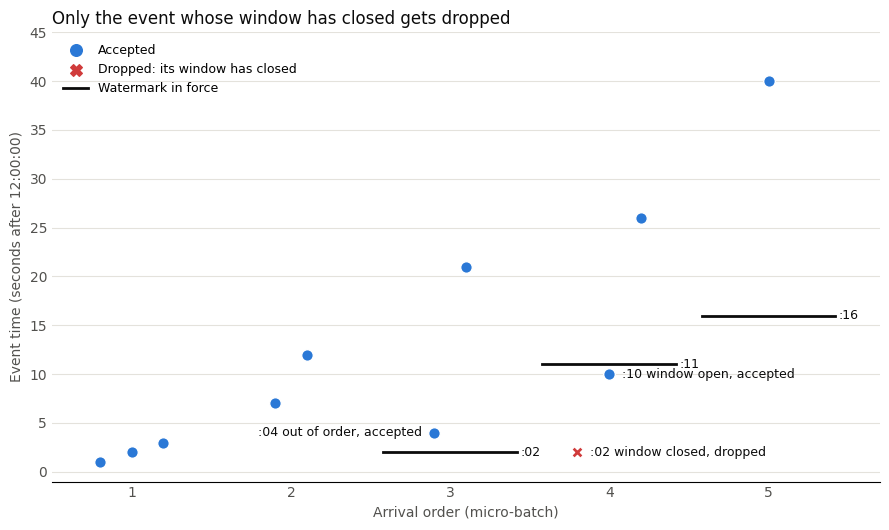

In [14]:
import matplotlib.pyplot as plt
from late_event_replay import TIMELINE

WATERMARK_DELAY, WINDOW_SIZE = 10, 5
ACCEPTED, DROPPED, INK, MUTED = "#2a78d6", "#d03b3b", "#0b0b0b", "#52514e"

fig, ax = plt.subplots(figsize=(9, 5.4))
newest = None
for number, batch in enumerate(TIMELINE, start=1):
    watermark = None if newest is None else newest - WATERMARK_DELAY
    if watermark is not None and watermark >= 0:
        ax.plot([number - 0.42, number + 0.42], [watermark, watermark], color=INK, linewidth=2, zorder=2)
        ax.text(number + 0.44, watermark, f":{watermark:02d}", color=INK, fontsize=9, va="center")
    spread = 0.2 * (len(batch) - 1)
    for position, reading in enumerate(batch):
        x = number - spread / 2 + 0.2 * position
        window_end = (reading.second // WINDOW_SIZE + 1) * WINDOW_SIZE
        dropped = watermark is not None and window_end <= watermark
        ax.scatter(x, reading.second, s=70, marker="X" if dropped else "o",
                   color=DROPPED if dropped else ACCEPTED, edgecolor="white", linewidth=1, zorder=3)
        if reading.note:
            left = number < 4        # labels point away from the watermark marks
            ax.annotate(f":{reading.second:02d} {reading.note}", (x, reading.second),
                        xytext=(-9 if left else 9, 0), textcoords="offset points",
                        ha="right" if left else "left", va="center", fontsize=9, color=INK)
    newest = max([newest or 0] + [r.second for r in batch])

ax.scatter([], [], s=70, marker="o", color=ACCEPTED, label="Accepted")
ax.scatter([], [], s=70, marker="X", color=DROPPED, label="Dropped: its window has closed")
ax.plot([], [], color=INK, linewidth=2, label="Watermark in force")

ax.set_title("Only the event whose window has closed gets dropped", loc="left", fontsize=12, color=INK)
ax.set_xlabel("Arrival order (micro-batch)", color=MUTED)
ax.set_ylabel("Event time (seconds after 12:00:00)", color=MUTED)
ax.set_xticks(range(1, len(TIMELINE) + 1))
ax.set_xlim(0.5, len(TIMELINE) + 0.7)
ax.set_ylim(-1, 45)
ax.set_yticks(range(0, 46, WINDOW_SIZE))
ax.grid(axis="y", color="#e4e2dc", linewidth=0.8)      # each band between gridlines is one window
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Each band between gridlines is one 5-second window. Reading from left to right, new events keep climbing and the watermark follows 10 seconds behind. Events plotted well below their neighbours are the out-of-order ones.

## Run A: `update` mode

We use `maxFilesPerTrigger=1` so that each simulator file is exactly one micro-batch, whatever the timing. That matches the table above. `temperatures` lists the readings in each window, so you can see exactly which events were counted.

Spark numbers its own batches from 0 and adds empty ones (more on that below), so our five batches of data become Spark batches 0, 2, 4, 6 and 8. Watch for window `12:00:00` coming back with a 4th reading in Spark batch 4, and for the `99.9` reading, which should never appear.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python late_event_replay.py
> ```
> To narrate each batch, add `--step` and press Enter for each one, leaving at least 2 seconds between batches. If you do, change `idle_seconds=15` in the cell below to `idle_seconds=120` so the cell does not stop while you talk.

In [15]:
REPLAY_DIR  = "tmp/late_replay_stream"
REPLAY_CKPT = "tmp/late_replay_ckpt"
REPLAY_OUT  = "out/late_replay_windows"
reset(REPLAY_DIR)

replay_schema = T.StructType([
    T.StructField("sensorID",    T.IntegerType()),
    T.StructField("event_time",  T.TimestampType()),
    T.StructField("temperature", T.DoubleType()),
])

replay_windows = (
    spark.readStream.schema(replay_schema)
    .option("maxFilesPerTrigger", 1)                     # one file = one micro-batch
    .csv(REPLAY_DIR)
    .withWatermark("event_time", "10 seconds")
    .groupBy(F.window("event_time", "5 seconds"))
    .agg(F.count("*").alias("readings"),
         F.round(F.avg("temperature"), 2).alias("avg_temp"),
         F.sort_array(F.collect_list("temperature")).alias("temperatures"))
    .select(F.date_format("window.start", "HH:mm:ss").alias("window_start"),
            F.date_format("window.end", "HH:mm:ss").alias("window_end"),
            "readings", "avg_temp", "temperatures")
)

def run_replay(mode):
    return (replay_windows.writeStream.format("console").outputMode(mode)
            .option("truncate", False)
            .option("checkpointLocation", REPLAY_CKPT)
            .trigger(processingTime="1 second").start())

reset(REPLAY_DIR, REPLAY_CKPT)
q = run_replay("update")
watch(q, cue="python late_event_replay.py", idle_seconds=15)

START THE SIMULATOR NOW:   python late_event_replay.py



-------------------------------------------
Batch: 0
-------------------------------------------
+------------+----------+--------+--------+------------------+
|window_start|window_end|readings|avg_temp|temperatures      |
+------------+----------+--------+--------+------------------+
|12:00:00    |12:00:05  |3       |70.0    |[68.0, 70.0, 72.0]|
+------------+----------+--------+--------+------------------+



-------------------------------------------
Batch: 1
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
+------------+----------+--------+--------+------------+

>> [batch 0] 3 rows arrived | newest event 12:00:03 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



>> [batch 1] 0 rows arrived | watermark 11:59:53 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



-------------------------------------------
Batch: 2
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
|12:00:05    |12:00:10  |1       |71.0    |[71.0]      |
|12:00:10    |12:00:15  |1       |73.0    |[73.0]      |
+------------+----------+--------+--------+------------+



>> [batch 2] 2 rows arrived | newest event 12:00:12 | watermark 11:59:53 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



... (9 outputs left out)

>> [batch 8] 1 rows arrived | newest event 12:00:40 | watermark 12:00:16 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



-------------------------------------------
Batch: 9
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
+------------+----------+--------+--------+------------+



>> [batch 9] 0 rows arrived | watermark 12:00:30 | LATE ROWS DROPPED 0 | groups closed 2 | groups open 1



Query stopped.


**Reading the result**

- Spark adds **empty batches of its own**, with `0 rows arrived` and an empty table. After a batch moves the watermark, Spark runs an extra batch with no data just to close windows. That is why you see ten batches when we sent five.
- The `watermark` figure matches the "watermark in force" column of the table.
- `LATE ROWS DROPPED 1` appears once, in Spark batch 6: the `99.9` reading.
- `groups closed` tells you when each window left memory.

## Run B: `append` mode

Same events, same watermark, a different output mode. Now each window appears **exactly once**, only when it closes, and with its final value. Compare *when* each window is printed with Run A.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python late_event_replay.py
> ```

In [16]:
reset(REPLAY_DIR, REPLAY_CKPT)
q = run_replay("append")
watch(q, cue="python late_event_replay.py", idle_seconds=15)

START THE SIMULATOR NOW:   python late_event_replay.py



-------------------------------------------
Batch: 0
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
+------------+----------+--------+--------+------------+



-------------------------------------------
Batch: 1
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
+------------+----------+--------+--------+------------+

>> [batch 0] 3 rows arrived | newest event 12:00:03 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



>> [batch 1] 0 rows arrived | watermark 11:59:53 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



-------------------------------------------
Batch: 2
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
+------------+----------+--------+--------+------------+



>> [batch 2] 2 rows arrived | newest event 12:00:12 | watermark 11:59:53 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



... (9 outputs left out)

>> [batch 8] 1 rows arrived | newest event 12:00:40 | watermark 12:00:16 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



-------------------------------------------
Batch: 9
-------------------------------------------
+------------+----------+--------+--------+------------+
|window_start|window_end|readings|avg_temp|temperatures|
+------------+----------+--------+--------+------------+
|12:00:20    |12:00:25  |1       |74.0    |[74.0]      |
|12:00:25    |12:00:30  |1       |76.0    |[76.0]      |
+------------+----------+--------+--------+------------+



>> [batch 9] 0 rows arrived | watermark 12:00:30 | LATE ROWS DROPPED 0 | groups closed 2 | groups open 1



Query stopped.


**Reading the result**

| Window | Readings | Why |
|---|---|---|
| `[:00-:05)` | 4: 68, 70, 72, 75 | Includes late `:04`, excludes dropped `:02` (99.9) |
| `[:05-:10)` | 1: 71 | |
| `[:10-:15)` | 2: 69, 73 | Includes `:10`, which arrived behind the watermark |
| `[:20-:25)` | 1: 74 | |
| `[:25-:30)` | 1: 76 | |
| `[:40-:45)` | never printed | The watermark stopped at `:30`, so this window never closed |

Notice the average for `[:00-:05)`: `71.25`. If the 99.9 reading had got in, it would be `76.98`.

## Run C: the same thing, to a file

Last, send the append results to a file, and remove the lateness with `--no-late`. The same events now arrive in time order, so nothing is out of order and nothing is dropped.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python late_event_replay.py --no-late
> ```

In [17]:
reset(REPLAY_DIR, REPLAY_CKPT, REPLAY_OUT)

q = (
    replay_windows.drop("temperatures").writeStream      # csv files cannot hold array columns
    .format("csv")
    .outputMode("append")
    .option("path", REPLAY_OUT)
    .option("header", "true")
    .option("checkpointLocation", REPLAY_CKPT)
    .trigger(processingTime="1 second")
    .start()
)
watch(q, cue="python late_event_replay.py --no-late", idle_seconds=15)

(spark.read.option("header", "true").csv(REPLAY_OUT)
    .orderBy("window_start")
    .show(truncate=False))

START THE SIMULATOR NOW:   python late_event_replay.py --no-late



>> [batch 0] 3 rows arrived | newest event 12:00:02 | watermark not set yet | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



>> [batch 1] 0 rows arrived | watermark 11:59:52 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



>> [batch 2] 2 rows arrived | newest event 12:00:04 | watermark 11:59:52 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



>> [batch 3] 0 rows arrived | watermark 11:59:54 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 1



>> [batch 4] 2 rows arrived | newest event 12:00:10 | watermark 11:59:54 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



... (3 outputs left out)

>> [batch 8] 1 rows arrived | newest event 12:00:40 | watermark 12:00:16 | LATE ROWS DROPPED 0 | groups closed 0 | groups open 3



>> [batch 9] 0 rows arrived | watermark 12:00:30 | LATE ROWS DROPPED 0 | groups closed 2 | groups open 1



Query stopped.


+------------+----------+--------+--------+
|window_start|window_end|readings|avg_temp|
+------------+----------+--------+--------+
|12:00:00    |12:00:05  |5       |76.98   |
|12:00:05    |12:00:10  |1       |71.0    |
|12:00:10    |12:00:15  |2       |71.0    |
|12:00:20    |12:00:25  |1       |74.0    |
|12:00:25    |12:00:30  |1       |76.0    |
+------------+----------+--------+--------+



With no late events, window `[:00-:05)` has all **5** readings, the 99.9 reading is included, and its average is `76.98`. The only difference between the two runs is the **order of arrival**. That is the whole idea of this session: when an event arrives can change the answer, and the watermark is how you decide how much of that you accept.

# Output Modes and Watermarks

| Output mode | Role of the watermark | Behaviour |
|-------------|----------------------|-------|
| `append`    | Required for aggregations | One final row per window, written after the window closes. Most delay, no revisions. Best for files. |
| `update`    | Optional, but it frees memory | Each changed window is re-emitted at every trigger. Fast, with revisions. Best for dashboards. |
| `complete`  | No effect on state | The whole result table is re-emitted at every trigger. No state is ever removed, so memory keeps growing. |

# Example 4: Deduplication -- The Same Reading, Twice

Most streaming systems promise **at-least-once** delivery: nothing is lost, but anything may arrive more than once. A sensor that gets no acknowledgement sends its reading again, even if the first copy got through. Count both copies and your totals are wrong.

Removing a duplicate takes **memory**. To recognise a reading as a repeat, Spark must remember every reading it has seen, in state. So the real question is the one watermarks already answer: *how long do we keep remembering?*

Each reading has a unique `readingID`, and retries come in two kinds:

- **Exact copy:** same `readingID`, same `event_time`.
- **Re-stamped retry:** same `readingID`, but the sensor put a new time on the retry.

**Three ways to deduplicate**

| Strategy | Code | What Spark remembers | How long |
|---|---|---|---|
| ID only | `.dropDuplicates(["readingID"])` | Every ID | **Forever**, so memory grows without limit |
| ID + event time | `.withWatermark(...)` then `.dropDuplicates(["readingID", "event_time"])` | Each ID + time pair | Until its `event_time` falls behind the watermark |
| Within watermark | `.withWatermark(...)` then `.dropDuplicatesWithinWatermark(["readingID"])` | Each ID | Until its first `event_time` + the delay falls behind the watermark |

Why does adding `event_time` to the key help? The watermark can only clear state that has a time attached. An ID alone has no time, so Spark never knows when to forget it.

**The script.** There are 7 different readings, r1 to r7, in 11 rows, with a 10-second watermark. After batch 4, the newest event is `:31`, so the watermark jumps to `:21`. Predict the last three columns before you run anything.

| Batch | Retry | Kind | ID only | ID + event time | Within watermark |
|---|---|---|---|---|---|
| 2 | r2 at `:02` | Exact copy, soon after | Removed | Removed | Removed |
| 3 | r3 at `:06` | Re-stamped, 3 seconds after `:03` | Removed | **Kept**: a new time is a new key | Removed |
| 5 | r1 at `:33` | Re-stamped, 32 seconds after `:01` | Removed | **Kept** | **Kept**: r1 was forgotten when its 10 seconds ran out |
| 5 | r4 at `:07` | Exact copy, much later | Removed | Dropped as late | Dropped as late |
| | | **Rows kept out of 11** | **7** | **9** | **8** |

In [22]:
DEDUP_DIR  = "tmp/duplicate_stream"
DEDUP_CKPT = "tmp/dedup_ckpt"
DEDUP_OUT  = "out/dedup"
reset(DEDUP_DIR)

reading_schema = T.StructType([
    T.StructField("readingID",   T.StringType()),
    T.StructField("sensorID",    T.IntegerType()),
    T.StructField("event_time",  T.TimestampType()),
    T.StructField("temperature", T.DoubleType()),
])

readings = (
    spark.readStream.schema(reading_schema)
    .option("maxFilesPerTrigger", 1)                     # one file = one micro-batch
    .csv(DEDUP_DIR)
)
watermarked = readings.withWatermark("event_time", "10 seconds")

strategies = {
    "no_dedup":         readings,
    "id_only":          readings.dropDuplicates(["readingID"]),
    "id_and_time":      watermarked.dropDuplicates(["readingID", "event_time"]),
    "within_watermark": watermarked.dropDuplicatesWithinWatermark(["readingID"]),
}

def dedup_to_console(df):
    readable = df.select("readingID", F.date_format("event_time", "HH:mm:ss").alias("event_time"), "temperature")
    return (readable.writeStream.format("console").outputMode("append")
            .option("truncate", False)
            .option("checkpointLocation", DEDUP_CKPT)
            .trigger(processingTime="1 second").start())

## Run A: ID + event time, to the console

The tables show the rows that **survive** deduplication. Notice that a reading appears as soon as it arrives. Unlike a windowed aggregation in `append` mode, deduplication does not wait for anything to close: the first copy goes straight through, and only later copies are removed.

In the progress lines, each "group" is one remembered reading. Our five batches of data are Spark batches 0, 2, 4, 6 and 8, as in Example 3.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python duplicate_replay.py
> ```

In [23]:
reset(DEDUP_DIR, DEDUP_CKPT)
q = dedup_to_console(strategies["id_and_time"])
watch(q, cue="python duplicate_replay.py")

START THE SIMULATOR NOW:   python duplicate_replay.py

-------------------------------------------
Batch: 0
-------------------------------------------
+---------+----------+-----------+
|readingID|event_time|temperature|
+---------+----------+-----------+
|r3       |12:00:03  |68.0       |
|r1       |12:00:01  |70.0       |
|r2       |12:00:02  |72.0       |
+---------+----------+-----------+

-------------------------------------------
Batch: 1
-------------------------------------------
>> [batch 0] 3 rows arrived | newest event 12:00:03 | watermark not set yet | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3

+---------+----------+-----------+
|readingID|event_time|temperature|
+---------+----------+-----------+
+---------+----------+-----------+

>> [batch 1] 0 rows arrived | watermark 11:59:53 | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3

-------------------------------------------
Batch: 2
--------------------------

**Reading the result**

- Spark batch 2: `DUPLICATES DROPPED 1`. That is r2's exact copy, removed by matching the state.
- Spark batch 4: r3 appears **again**, at `12:00:06`. The new time makes a new key, so this duplicate got through.
- Spark batch 7, an empty batch: `groups open` falls from 5 to 1. The watermark jumped to `:21`, so Spark forgot almost everything.
- Spark batch 8: r1 appears again, and `LATE ROWS DROPPED 1` is r4's late copy. Spark no longer remembers r4, but it does not need to. An `event_time` of `:07` is behind the watermark, so any row that old is dropped.

That last point is why this strategy is safe for **exact copies**, even after it forgets them. Its weakness is re-stamped retries.

## Run B: Within watermark, to the console

`dropDuplicatesWithinWatermark` was made for re-stamped retries. It matches on the ID alone, and still knows when to forget, because it remembers each ID until the first `event_time` + the delay falls behind the watermark. The time is stored with the ID rather than being part of it.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python duplicate_replay.py
> ```

In [24]:
reset(DEDUP_DIR, DEDUP_CKPT)
q = dedup_to_console(strategies["within_watermark"])
watch(q, cue="python duplicate_replay.py")

START THE SIMULATOR NOW:   python duplicate_replay.py

-------------------------------------------
Batch: 0
-------------------------------------------
+---------+----------+-----------+
|readingID|event_time|temperature|
+---------+----------+-----------+
|r2       |12:00:02  |72.0       |
|r1       |12:00:01  |70.0       |
|r3       |12:00:03  |68.0       |
+---------+----------+-----------+

-------------------------------------------
Batch: 1
-------------------------------------------
+---------+----------+-----------+
|readingID|event_time|temperature|
+---------+----------+-----------+
+---------+----------+-----------+

>> [batch 0] 3 rows arrived | newest event 12:00:03 | watermark not set yet | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3

>> [batch 1] 0 rows arrived | watermark 11:59:53 | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3

-------------------------------------------
Batch: 2
--------------------------

**Reading the result**

- Spark batch 4 now shows only r5, with `DUPLICATES DROPPED 1`. The retry of r3 at `:06` was caught, because r3 is remembered until `:03 + 10 = :13` falls behind the watermark.
- Spark batch 8 still shows r1 at `:33`. Its retry came 32 seconds after the original, after the watermark had passed `:11` and r1 had been forgotten. **No strategy with a time limit can catch a retry that arrives after the limit.**

## Run C: All strategies on the same data, to files

Now all four queries run at once on one replay, each with its own output folder and checkpoint. This time we include `no_dedup` and `id_only`. Each writes one row per surviving reading, so the output files can be compared directly.

> **▶ Simulator cue.** Run the next cell. When it prints `START THE SIMULATOR NOW`, run this in the terminal:
> ```
> python duplicate_replay.py
> ```

In [ ]:
reset(DEDUP_DIR, DEDUP_CKPT, DEDUP_OUT)

queries = [
    df.writeStream.queryName(name).format("csv").outputMode("append")
      .option("path", f"{DEDUP_OUT}/{name}")
      .option("checkpointLocation", f"{DEDUP_CKPT}/{name}")
      .trigger(processingTime="1 second").start()
    for name, df in strategies.items()
]
watch(*queries, cue="python duplicate_replay.py")

START THE SIMULATOR NOW:   python duplicate_replay.py



>> [no_dedup, batch 0] 3 rows arrived



>> [id_only, batch 0] 3 rows arrived | watermark not set yet | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3



>> [id_and_time, batch 0] 3 rows arrived | newest event 12:00:03 | watermark not set yet | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3



>> [within_watermark, batch 0] 3 rows arrived | newest event 12:00:03 | watermark not set yet | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3



>> [id_and_time, batch 1] 0 rows arrived | watermark 11:59:53 | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3



... (22 outputs left out)

>> [within_watermark, batch 8] 3 rows arrived | newest event 12:00:36 | watermark 12:00:21 | LATE ROWS DROPPED 1 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 4



>> [id_and_time, batch 9] 0 rows arrived | watermark 12:00:26 | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 0 | groups open 3



>> [within_watermark, batch 9] 0 rows arrived | watermark 12:00:26 | LATE ROWS DROPPED 0 | DUPLICATES DROPPED 0 | groups closed 1 | groups open 3



Query stopped.


In [ ]:
survivors = None
for name in strategies:
    rows = spark.read.schema(reading_schema).csv(f"{DEDUP_OUT}/{name}").withColumn("strategy", F.lit(name))
    survivors = rows if survivors is None else survivors.unionByName(rows)

print("Rows kept for each reading (a correct result is 1 everywhere):")
(survivors.groupBy("readingID").pivot("strategy", list(strategies)).count()
    .fillna(0)
    .orderBy("readingID")
    .show(truncate=False))

print("Summary:")
(survivors.groupBy("strategy")
    .agg(F.count("*").alias("rows_kept"),
         F.countDistinct("readingID").alias("different_readings"),
         F.round(F.avg("temperature"), 2).alias("avg_temp"))
    .withColumn("extra_rows", F.col("rows_kept") - F.col("different_readings"))
    .orderBy(F.desc("rows_kept"))
    .show(truncate=False))

Rows kept for each reading (a correct result is 1 everywhere):


+---------+--------+-------+-----------+----------------+
|readingID|no_dedup|id_only|id_and_time|within_watermark|
+---------+--------+-------+-----------+----------------+
|r1       |2       |1      |2          |2               |
|r2       |2       |1      |1          |1               |
|r3       |2       |1      |2          |1               |
|r4       |2       |1      |1          |1               |
|r5       |1       |1      |1          |1               |
|r6       |1       |1      |1          |1               |
|r7       |1       |1      |1          |1               |
+---------+--------+-------+-----------+----------------+

Summary:


+----------------+---------+------------------+--------+----------+
|strategy        |rows_kept|different_readings|avg_temp|extra_rows|
+----------------+---------+------------------+--------+----------+
|no_dedup        |11       |7                 |71.27   |4         |
|id_and_time     |9        |7                 |71.22   |2         |
|within_watermark|8        |7                 |71.63   |1         |
|id_only         |7        |7                 |71.86   |0         |
+----------------+---------+------------------+--------+----------+



**What this shows**

- `no_dedup` counts 11 rows for 7 readings, so any "number of readings" metric is 57% too high.
- `id_only` gets it exactly right here, but only because this stream lasts 40 seconds. Its memory grows with every new reading, for as long as the query runs, which is a serious cost on a stream that runs for months.
- `id_and_time` and `within_watermark` keep memory bounded, at the cost of some leftover duplicates.

**Choosing a strategy**

| Your retries... | Use |
|---|---|
| ...are exact copies | `withWatermark` + `dropDuplicates` with the ID and `event_time` |
| ...may carry a new timestamp | `withWatermark` + `dropDuplicatesWithinWatermark` on the ID |
| ...and the stream is small and short-lived | `dropDuplicates` on the ID alone may be good enough |

**Two practical rules**

- **Set the delay longer than your slowest retry.** If sensors retry for up to 5 minutes, a 10-second watermark will let duplicates through. A longer delay means more memory, which is the same trade-off as in Example 1.
- **Deduplicate before you aggregate.** Once a duplicate has been counted in a window, it cannot be taken back out.

**Watch out:** in the watermark strategies, "dropped as late" applies to every row, not just to duplicates. A genuine first-time reading older than the watermark is dropped too.

**Try it.** Rerun Run A with `python duplicate_replay.py --no-duplicates`. All 7 readings get through, and `DUPLICATES DROPPED` stays at 0. Then change `"10 seconds"` to `"40 seconds"` where `watermarked` is defined, rerun that cell and Run B with the normal command, and predict what happens to r1 at `:33`.

# Key Takeaways

- **Event time** says when something happened, **processing time** says when Spark saw it. Windows should use event time.
- `watermark = newest event time seen - delay`. It moves only when newer events arrive.
- A window closes when `window end <= watermark`. A late event is dropped only if its window has already closed.
- A watermark is a minimum wait, not an exact cutoff: events within the delay are always counted, and later ones usually are not.
- Tumbling windows put each event in one window. Sliding windows put it in several, so do not sum them.
- A longer watermark means more complete results, later output, and more memory. That trade-off is a business decision.
- To deduplicate a stream, combine a unique ID with a watermark, so Spark can forget old IDs. `dropDuplicatesWithinWatermark` also catches retries that carry a new timestamp, but only while the ID is still remembered.
- To test watermark behaviour, data must arrive over time. `availableNow` puts everything in one batch.

# Shutdown Spark when done

In [18]:
spark.stop()